# Lab 08: Model Evaluation
### COMM 4259 <br> <i>Foundations of Machine Learning and AI</i>

© Jingjing Li- Ask for permission for using/quoting: jingjing.li@virginia.edu

## Lab Prep
* If you would like to see my screen on your computer, you can use a web browser to log in to Zoom, turn off the speaker and mute yourself.
    - Section 001, 11:00 a.m. – 12:15 p.m.: https://mcintire.zoom.us/j/95993311893?pwd=NmabjMgwCFyKkxzib3qMFahEDkkaSI.1
    - Section 002, 2:00 – 3:15 p.m.: https://mcintire.zoom.us/j/97629389481?pwd=GA37uPdbfC0154k4M3n17SGf6qaYCg.1
* Have VS Code open with your `comm4259-work` folder before we start.

## Lab Rules
* Raise hands for questions
* Be prepared to share your screen for Q & A or exercises

# Before You Start: Save the Lab Files to GitHub
1. Download `lab_08.zip` from Canvas, move it into your `comm4259-work` folder, and unzip it there. You now have `comm4259-work/lab_08/` with this notebook and its data.
2. In VS Code, open `comm4259-work` and a terminal (Terminal > New Terminal). From `comm4259-work`, commit and push the files you just downloaded:

```
git add .
git commit -m "Lab 08: downloaded the lab files"
git push
```

Your repository now has the starting copy, and your commit at the end of class shows the work you did in the lab.

# Learning Objectives
In this lab you evaluate one decision tree on the wine quality data. You will:
1. Explain why a model must be judged on data it did not learn from.
2. Estimate how well a model will do on new data in three ways: **holdout**, **K-fold cross validation**, and the **bootstrap**.
3. Read a **confusion matrix** and compute **accuracy, precision, recall and F1** from it, first by hand and then with scikit-learn.
4. Use a **cost matrix** to compute what a model's mistakes cost, and see how the costs change what the model is worth.
5. Save the evaluation as a **Claude Code skill** and check the agent's numbers against your own.

There are seven exercises: Exercises 1 to 3 are done by hand in Parts 2 to 4, and Exercises 4 to 7 use Claude Code in Part 5.

# Part 1: The Wine Quality Data
Each row is one wine. The 11 input columns are lab measurements (acidity, sugar, alcohol and so on), and the class label, `quality`, is **Good** or **Poor**.

## Import libraries

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay, classification_report
from sklearn.utils import resample

## Read the data

In [ ]:
wine = pd.read_csv("WineQuality.csv")
print(wine.shape)
wine.head()

## Examine the class label

In [ ]:
print(wine["quality"].value_counts())
print(wine["quality"].value_counts(normalize=True).map("{:.2%}".format))

About 61% of the wines are Poor. A "model" that always answers Poor is therefore right about 61% of the time. This is the **baseline**: a real model has to do better than this to be useful.

## Separate the input features and the class label

In [ ]:
X = wine.drop("quality", axis=1)   # the 11 input features
y = wine["quality"]                # the class label: Good or Poor
print(X.shape, y.shape)

## The model we evaluate
We use the same decision tree everywhere in this lab, so that only the **evaluation method** changes.

In [ ]:
def make_tree(depth=5):
    return DecisionTreeClassifier(max_depth=depth, random_state=1)

# Part 2: Three Ways to Estimate Accuracy
## Why not test on the training data?
First, train the tree on **all** the data and test it on the **same** data.

In [ ]:
tree = make_tree()
tree.fit(X, y)
print(f"Training accuracy: {accuracy_score(y, tree.predict(X)):.2%}")

This number is too optimistic. The tree has already seen the answers for these wines. What we want to know is how well it does on wines it has **not** seen. The three methods below each keep some data out of training to answer that question.

In Lecture 06 you saw the difference between offline evaluation and online deployment. A shop that stocks wines based on the model is the online deployment; everything in this lab is offline evaluation, an estimate of how the model will do once it is used.

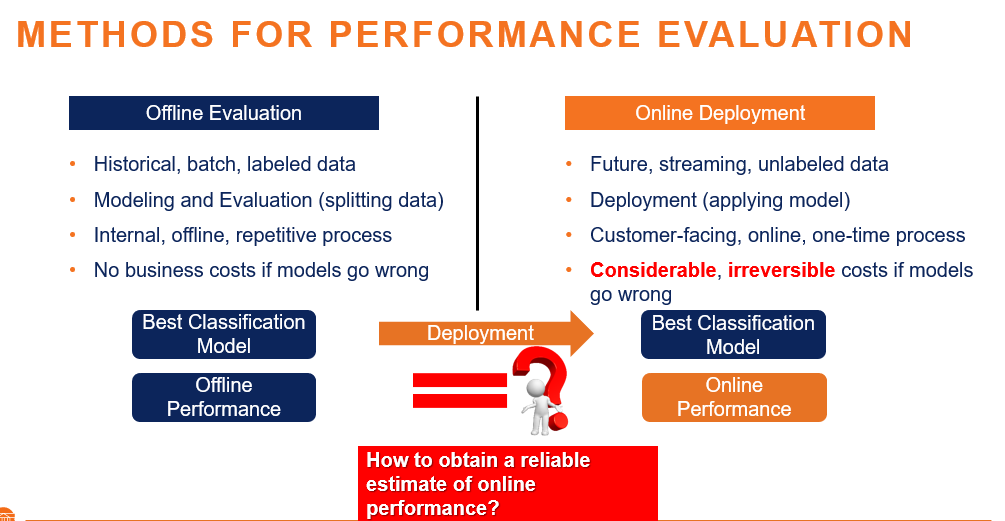

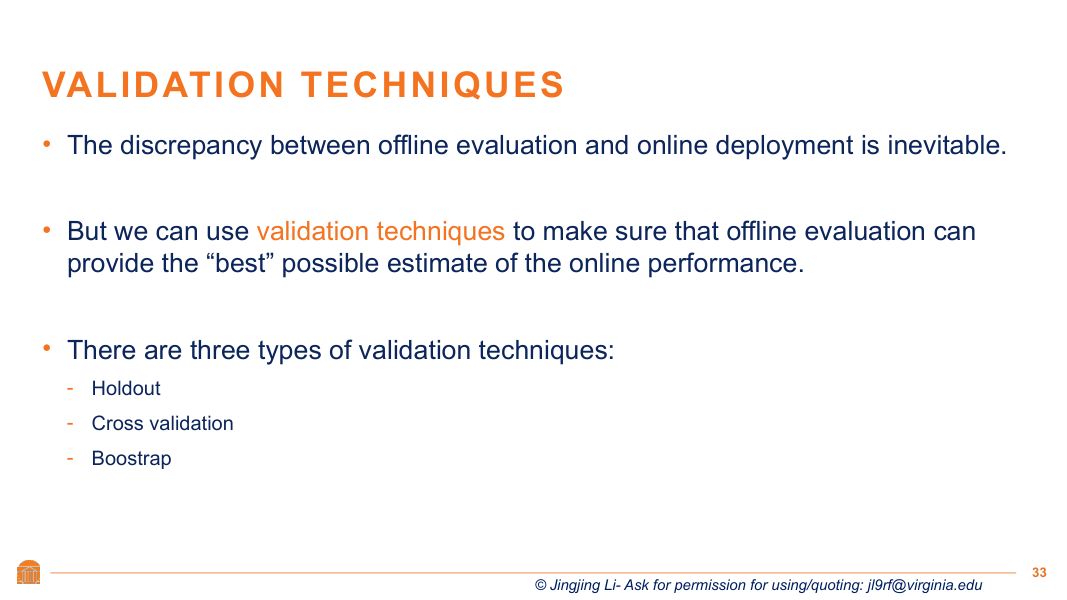

## 2.1 Holdout
Split the data once: 70% to train, 30% to test. `stratify=y` keeps the same share of Good and Poor wines in both parts.

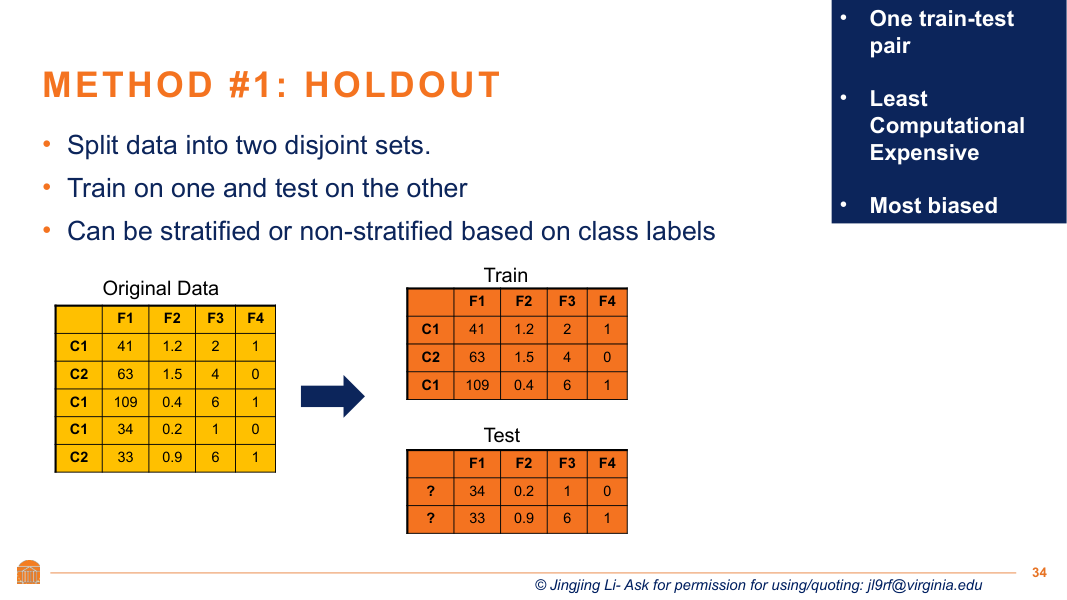

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, stratify=y, random_state=1)
print("Train:", X_train.shape, " Test:", X_test.shape)

tree = make_tree()
tree.fit(X_train, y_train)          # learn from the training part only
y_pred = tree.predict(X_test)       # predict the test part
print(f"Holdout accuracy: {accuracy_score(y_test, y_pred):.2%}")

The holdout result depends on which wines land in the test part. Change `random_state` to get a different split:

In [ ]:
for seed in [1, 2, 3, 4, 5]:
    X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.3, stratify=y, random_state=seed)
    acc = accuracy_score(y_te, make_tree().fit(X_tr, y_tr).predict(X_te))
    print(f"random_state = {seed}  holdout accuracy: {acc:.2%}")

## 2.2 K-fold cross validation
Cross validation repeats the holdout idea so that **every** wine is tested once. With 5 folds, the data is cut into 5 parts. Each part takes a turn as the test set while the other 4 parts train the tree, which gives 5 accuracy scores.

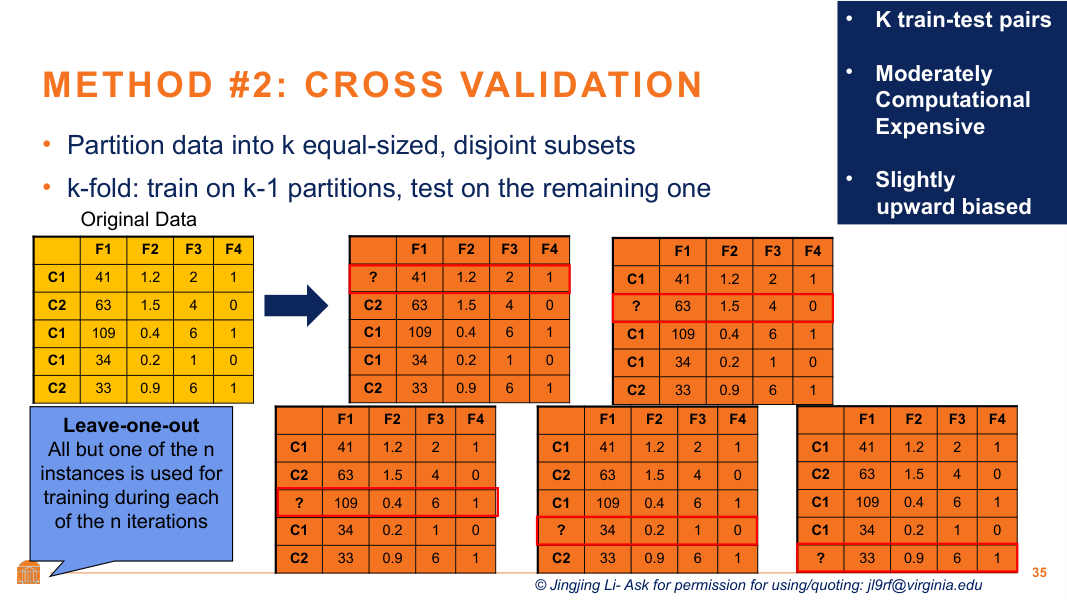

The final estimate is the average of the rounds:

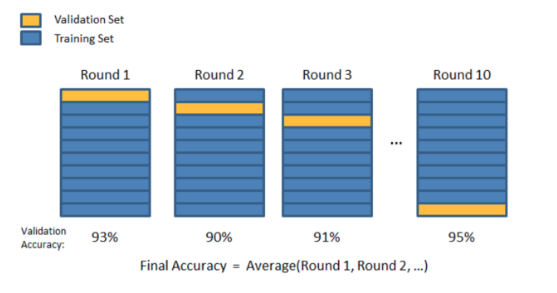

In [ ]:
folds = StratifiedKFold(n_splits=5, shuffle=True, random_state=1)
scores = cross_val_score(make_tree(), X, y, cv=folds, scoring="accuracy")

print("Accuracy in each fold:", ", ".join(f"{s:.2%}" for s in scores))
print(f"Mean: {scores.mean():.2%}  Standard deviation: {scores.std():.2%}")

## 2.3 Bootstrap
The bootstrap draws a new training set of the same size **with replacement**: some wines are picked twice or more, and others are not picked at all. The wines that were not picked are the test set for that round. We repeat this 100 times.

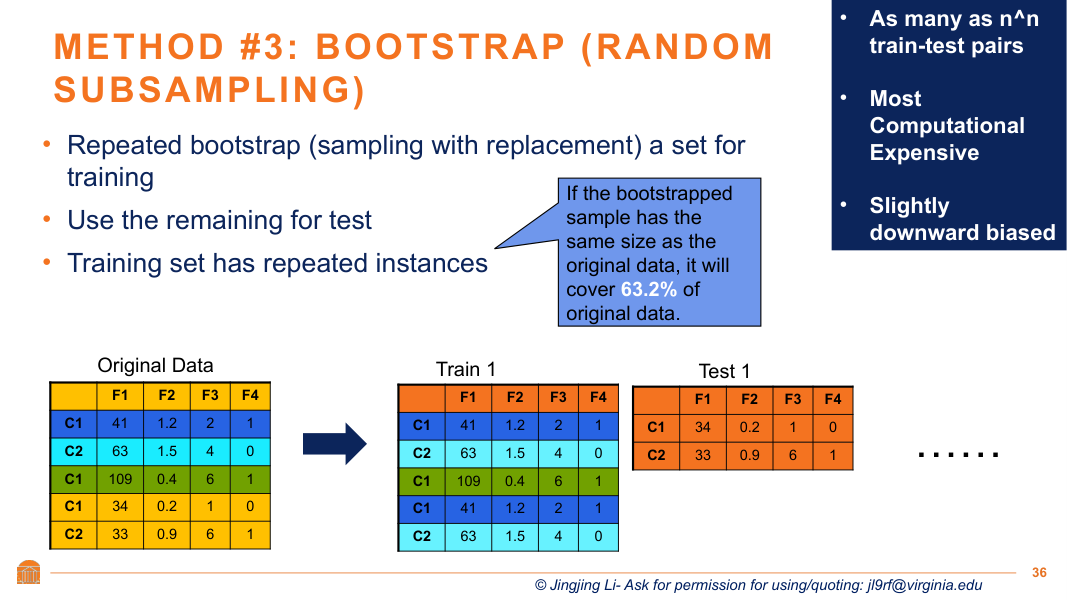

The slide says a bootstrap sample of the same size covers about 63.2% of the original data, so about 36.8% is left out for testing. The first line of the output below checks this on the wine data.

In [ ]:
n = len(X)
all_rows = np.arange(n)
boot_scores = []

for b in range(100):
    train_rows = resample(all_rows, replace=True, n_samples=n, random_state=b)   # draw n rows with replacement
    test_rows = np.setdiff1d(all_rows, train_rows)                                # the rows never drawn
    tree = make_tree().fit(X.iloc[train_rows], y.iloc[train_rows])
    boot_scores.append(accuracy_score(y.iloc[test_rows], tree.predict(X.iloc[test_rows])))

boot_scores = np.array(boot_scores)
print(f"Share of rows left out in the last round: {len(test_rows) / n:.2%}")
print(f"Mean: {boot_scores.mean():.2%}  Standard deviation: {boot_scores.std():.2%}")
print(f"Middle 95% of the rounds: {np.percentile(boot_scores, 2.5):.2%} to {np.percentile(boot_scores, 97.5):.2%}")

In [ ]:
plt.hist(boot_scores, bins=15)
plt.xlabel("Accuracy on the left-out wines")
plt.ylabel("Number of bootstrap rounds")
plt.title("100 bootstrap estimates of accuracy")
plt.show()

## Compare the three methods
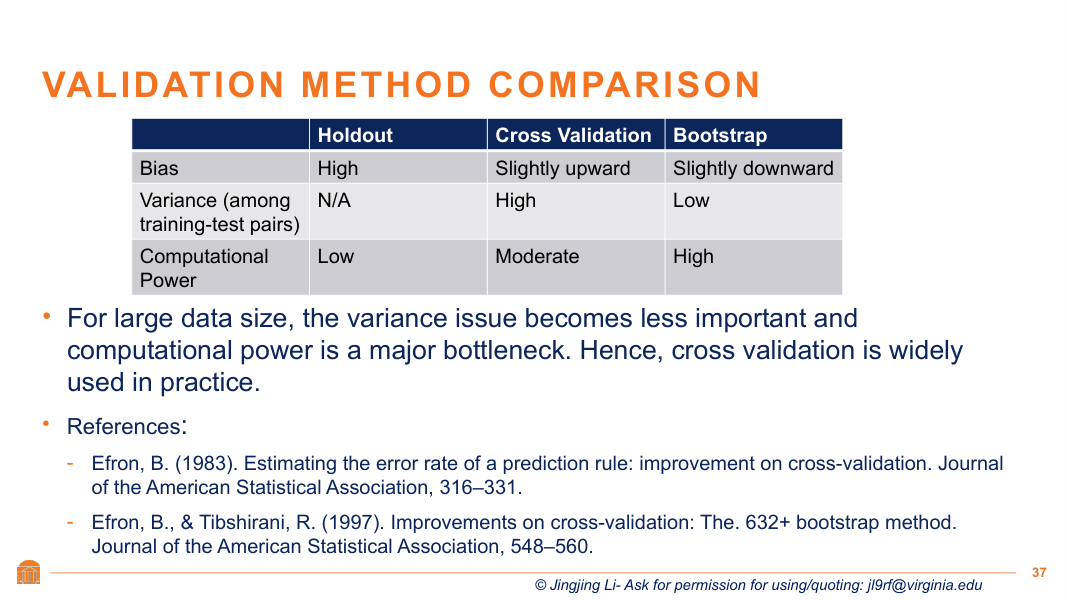

## Exercise 1: Compare the estimates

<div style="background-color:#DFF5DC; color:#14532D; border:1px solid #A5D6A7; border-left:5px solid #2E7D32; padding:15px; margin-bottom:20px; border-radius:4px;">
<b>Exercise 1:</b> The table below collects the numbers from your output above. Look at it, then answer these two questions in one sentence each, in the cell below the table.
<ol>
<li>Which row has the highest accuracy? Why is that number too optimistic? (Hint: which wines was the tree tested on?)</li>
<li>Which method would you use to report the accuracy to a manager: holdout, cross validation or bootstrap? Give one reason.</li>
</ol>
</div>

| Method | Accuracy | How much it varies |
|---|---|---|
| Baseline (always Poor) | 60.74% | (none) |
| Training data (Part 2 start) | 87.11% | (none) |
| Holdout, random_state = 1 | 85.80% | 83.95% to 85.80% over random_state 1 to 5 |
| 5-fold cross validation | 84.74% | standard deviation 0.81% |
| Bootstrap, 100 rounds | 83.78% | middle 95%: 81.22% to 85.97% |

Your answers:
1.
2.

# Part 3: Beyond Accuracy: the Confusion Matrix
Accuracy treats every mistake the same. A wine shop does not: calling a Poor wine Good (and stocking it) is a different mistake from calling a Good wine Poor. The **confusion matrix** counts each kind of right and wrong answer.

We use the holdout model from 2.1, and we treat **Good** as the **positive** class.

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, stratify=y, random_state=1)
tree = make_tree().fit(X_train, y_train)
y_pred = tree.predict(X_test)

labels = ["Good", "Poor"]   # positive class first
cm = confusion_matrix(y_test, y_pred, labels=labels)
print(cm)
ConfusionMatrixDisplay(cm, display_labels=labels).plot()
plt.show()

Rows are the **actual** class and columns are the **predicted** class:

| | Predicted Good | Predicted Poor |
|---|---|---|
| **Actual Good** | True Positive (TP) | False Negative (FN) |
| **Actual Poor** | False Positive (FP) | True Negative (TN) |

## Compute the metrics by hand

In [ ]:
TP, FN = cm[0, 0], cm[0, 1]
FP, TN = cm[1, 0], cm[1, 1]
print("TP =", TP, " FN =", FN, " FP =", FP, " TN =", TN)

accuracy = (TP + TN) / (TP + TN + FP + FN)          # share of all answers that are right
precision = TP / (TP + FP)                          # of the wines called Good, the share that are Good
recall = TP / (TP + FN)                             # of the Good wines, the share the model finds
f1 = 2 * precision * recall / (precision + recall)  # one number that balances precision and recall

print(f"Accuracy:  {accuracy:.2%}")
print(f"Precision: {precision:.2%}")
print(f"Recall:    {recall:.2%}")
print(f"F1:        {f1:.2%}")

## The same metrics with scikit-learn
`classification_report` gives precision, recall and F1 for **each** class. It prints decimals, so we take its results as a dictionary (`output_dict=True`) and print them as percentages. Check that the Good line matches your numbers above.

In [ ]:
report = classification_report(y_test, y_pred, labels=labels, output_dict=True)
for name in labels:
    r = report[name]
    print(f"{name}:  precision {r['precision']:.2%}  recall {r['recall']:.2%}  F1 {r['f1-score']:.2%}  ({r['support']:.0f} wines)")

## Exercise 2: Which class is positive?

<div style="background-color:#DFF5DC; color:#14532D; border:1px solid #A5D6A7; border-left:5px solid #2E7D32; padding:15px; margin-bottom:20px; border-radius:4px;">
<b>Exercise 2:</b> Precision, recall and F1 depend on which class you call <b>positive</b>. Now treat <b>Poor</b> as the positive class. The cell below already picks the four cells of the <b>same</b> confusion matrix for you.
<ol>
<li>Copy the four formula lines from "Compute the metrics by hand" above into the cell below, and add <code>_poor</code> to each name (for example <code>precision_poor = TP_poor / (TP_poor + FP_poor)</code>). Run the cell.</li>
<li>Check your four numbers against the <b>Poor</b> line of the scikit-learn output above, and fill in the table.</li>
<li>One metric does not change when you switch the positive class. Which one?</li>
</ol>
</div>

In [ ]:
# Exercise 2: Poor is the positive class. Use the same cm as above.
TP_poor = cm[1, 1]   # actual Poor, predicted Poor
FN_poor = cm[1, 0]   # actual Poor, predicted Good
FP_poor = cm[0, 1]   # actual Good, predicted Poor
TN_poor = cm[0, 0]   # actual Good, predicted Good
print("TP =", TP_poor, " FN =", FN_poor, " FP =", FP_poor, " TN =", TN_poor)

# Add the four formula lines here (accuracy_poor, precision_poor, recall_poor, f1_poor), then print them

| Metric | Good is positive | Poor is positive (yours) |
|---|---|---|
| Accuracy | 85.80% | |
| Precision | 84.41% | |
| Recall | 78.30% | |
| F1 | 81.24% | |

Your answer:

# Part 4: The Cost Matrix
A wine shop uses the model to decide which wines to stock as Good. Suppose the two mistakes cost:
- **False Positive** (a Poor wine called Good and stocked): **\$10** in returns and lost customers.
- **False Negative** (a Good wine called Poor and not stocked): **\$2** in lost profit.
- Right answers cost **\$0**.

The **cost matrix** has the same layout as the confusion matrix:

| Cost | Predicted Good | Predicted Poor |
|---|---|---|
| **Actual Good** | 0 | 2 |
| **Actual Poor** | 10 | 0 |

The **total cost** of a model multiplies each cell of its confusion matrix by the matching cell of the cost matrix, and adds them up. We compare the tree with the **baseline** from Part 1, which calls every wine Poor.

In [ ]:
cost = np.array([[0, 2],
                 [10, 0]])

# The baseline: call every wine in the test set Poor
cm_base = confusion_matrix(y_test, ["Poor"] * len(y_test), labels=labels)
print("Baseline confusion matrix:")
print(cm_base)

total_tree = (cm * cost).sum()       # cell by cell, then add
total_base = (cm_base * cost).sum()
print(f"Total cost, tree:     ${total_tree}   per wine: ${total_tree / cm.sum():.2f}")
print(f"Total cost, baseline: ${total_base}   per wine: ${total_base / cm_base.sum():.2f}")

| Model | Accuracy | False Positives (\$10 each) | False Negatives (\$2 each) | Total cost |
|---|---|---|---|---|
| Decision tree | 85.80% | 46 | 69 | \$598 |
| Baseline (always Poor) | 60.74% | 0 | 318 | \$636 |

The tree is 25 points more accurate, but it saves only \$38. The baseline never stocks a Poor wine, so it never makes the expensive mistake; its errors are all the cheap kind.

## Exercise 3: Change the costs

<div style="background-color:#DFF5DC; color:#14532D; border:1px solid #A5D6A7; border-left:5px solid #2E7D32; padding:15px; margin-bottom:20px; border-radius:4px;">
<b>Exercise 3:</b> Suppose the shop's situation is the other way round: a missed Good wine (False Negative) costs <b>&#36;10</b> and a stocked Poor wine (False Positive) costs <b>&#36;2</b>. The new cost matrix is:
<table>
<tr><th>Cost</th><th>Predicted Good</th><th>Predicted Poor</th></tr>
<tr><th>Actual Good</th><td>0</td><td><b>10</b></td></tr>
<tr><th>Actual Poor</th><td><b>2</b></td><td>0</td></tr>
</table>
<ol>
<li>Change the four numbers of <code>cost2</code> in the cell below to this matrix, run it, and fill in the table.</li>
<li>How much does the tree save over the baseline now? (Subtract the tree's cost from the baseline's cost.)</li>
<li>Compare with the original costs, where the tree saved only &#36;38. In one sentence: why does the same tree save so much more now?</li>
</ol>
</div>

In [ ]:
cost2 = np.array([[0, 2],     # change these four numbers
                  [10, 0]])

print(f"Total cost, tree:     ${(cm * cost2).sum()}")
print(f"Total cost, baseline: ${(cm_base * cost2).sum()}")

| Model | Total cost, original costs | Total cost, your new costs |
|---|---|---|
| Decision tree | \$598 | |
| Baseline (always Poor) | \$636 | |

Your answers (questions 2 and 3):
2.
3.

# Part 5: Save the Evaluation as a Skill (Claude Code)
In Parts 2 to 4 you evaluated a model with a fixed set of steps. You will evaluate models again in Lab 9, Lab 10 and your project, so it is worth saving the steps as a **skill**.

**Finish Parts 2 to 4 first.** Your numbers are the check on the agent's numbers.

<div style="background-color:#FFF4CE; color:#5C4200; border:1px solid #E8C86E; border-left:5px solid #D69E00; padding:15px; border-radius:4px;">
<b>Note: What is a skill in Claude Code?</b><br>
A <b>skill</b> is a short instruction file that Claude Code can reuse for one kind of task. It lives in its own folder, as <code>.claude/skills/&lt;skill-name&gt;/SKILL.md</code>, and starts with a <b>name</b> and a one- or two-sentence <b>description</b>.<br><br>
At the start of each session, Claude Code reads only the names and descriptions. It loads the full instructions when a task matches the description, or when you type <code>/</code> and the skill name.<br><br>
A skill saved in <code>comm4259-work/.claude/skills/</code> works in every lab and assignment folder inside <code>comm4259-work</code>, like your <code>CLAUDE.md</code>. <code>CLAUDE.md</code> holds <b>rules for every session</b>; a skill holds <b>the steps for one task</b>.<br><br>
<b>A skill is not a script.</b> In Exercise 4 the agent writes a script, <code>evaluate.py</code>; in Exercise 5 it saves the steps behind that script as a skill.
<table>
<tr><th></th><th>Script (<code>evaluate.py</code>)</th><th>Skill (<code>SKILL.md</code>)</th></tr>
<tr><th>Written in</th><td>Python code</td><td>Plain-language instructions</td></tr>
<tr><th>Who runs it</th><td>Python, when you type <code>python evaluate.py</code></td><td>Claude Code, when a task matches or you type <code>/evaluate-classifier</code></td></tr>
<tr><th>What it does</th><td>Exactly the same steps on the same file, every time</td><td>Asks for the file, target, model and costs, then writes or adapts code for the new task</td></tr>
<tr><th>New data</th><td>You edit the code by hand</td><td>You answer its questions</td></tr>
<tr><th>Checking</th><td>Same input, same output</td><td>The agent can still make mistakes, so you check its numbers</td></tr>
</table>
</div>

## Exercise 4: Do the task once with Claude Code

<div style="background-color:#DFF5DC; color:#14532D; border:1px solid #A5D6A7; border-left:5px solid #2E7D32; padding:15px; margin-bottom:20px; border-radius:4px;">
<b>Exercise 4:</b>
<ol>
<li>In the VS Code terminal, from <code>comm4259-work</code>, make a folder for this part: <code>mkdir lab_08/skill_demo</code></li>
<li>Start <code>claude</code> in <code>comm4259-work</code>. <b>Keep this one session open until the end of Part 5</b>, as in Lab 07. Open a second terminal with the <b>+</b> in the terminal panel whenever you need to run something else.</li>
<li>Press <b>Shift+Tab</b> until the bottom line shows <b>plan mode</b>, and paste the prompt below. Find the five parts from Lab 07 in it (goal, context, constraints, artifacts, finished).</li>
<li>Review the plan, then approve it. When the script is built, run it in the <b>second terminal</b>, from <code>comm4259-work</code>: <code>python lab_08/skill_demo/evaluate.py</code></li>
<li>Check the agent's numbers against yours in the table below (no AI). If a number does not match, find out why (for example, a different split, <code>random_state</code>, number of folds, or positive class) and ask the agent to fix it. Fixes you make here will be saved in the skill.</li>
</ol>
</div>

Prompt for step 3:

```
Work only in lab_08/skill_demo/: create and edit files only there.
Write lab_08/skill_demo/evaluate.py to evaluate a classifier on lab_08/WineQuality.csv. The target is quality; the positive class is Good.
- Model: DecisionTreeClassifier(max_depth=5, random_state=1).
- Holdout: stratified 70/30 split with random_state=1. Report accuracy, and precision, recall and F1 for Good.
- Print the confusion matrix with the rows and columns in the order Good, Poor, and save it as a PNG in lab_08/skill_demo/.
- Total cost with this cost matrix (rows actual, columns predicted, order Good, Poor): [[0, 2], [10, 0]].
- Cross validation: StratifiedKFold with 5 splits, shuffle=True, random_state=1. Report the mean accuracy +/- the standard deviation.
Print the results in a short table, with every rate as a percentage with two decimals (for example 85.80%).
```

| Number | Your result (Parts 2 to 4) | The agent's script | Match? |
|---|---|---|---|
| Holdout accuracy | 85.80% | | |
| Cross validation accuracy | 84.74% +/- 0.81% | | |
| Total cost | \$598 | | |

## Exercise 5: Save the task as a skill

<div style="background-color:#DFF5DC; color:#14532D; border:1px solid #A5D6A7; border-left:5px solid #2E7D32; padding:15px; margin-bottom:20px; border-radius:4px;">
<b>Exercise 5:</b>
<ol>
<li>In the same session, switch out of plan mode (Shift+Tab) and paste the prompt below.</li>
<li>Claude Code always asks before it writes inside a <code>.claude</code> folder, because that folder holds its own settings. Read the path; if it is <code>.claude/skills/evaluate-classifier/SKILL.md</code>, answer Yes.</li>
<li>Open <code>comm4259-work/.claude/skills/evaluate-classifier/SKILL.md</code> in VS Code (VS Code shows the hidden <code>.claude</code> folder), and answer these four questions in the cell below:
<ol type="a">
<li>What are the <code>name</code> and <code>description</code> at the top of the file?</li>
<li>Which steps does the skill list? Are any steps from Parts 2 to 4 missing?</li>
<li>Does anything in it only fit the wine data (a file name, a column name)? If so, ask the agent to make it general.</li>
<li>Did it keep the corrections you made in Exercise 4?</li>
</ol></li>
<li><b>Export the session now</b>, before Exercise 6 clears it, with the export command below. It is a Claude Code command, not a prompt.</li>
</ol>
</div>

Prompt for step 1:

```
Save what we just did as a skill named evaluate-classifier, in .claude/skills/evaluate-classifier/SKILL.md inside comm4259-work. You may create that one file outside lab_08/skill_demo/.
The skill should work for any CSV file: it should ask me for the file, the target column, the positive class, the columns to drop, the model and its settings, the cost matrix, and the folder for its output.
Include the corrections I made in this session.
Keep the description to one or two sentences that say when to use the skill.
```

Export command for step 4:

```
/export lab_08/skill_demo/lab_08_build.md
```

Your answers to the four questions:
1.
2.
3.
4.

## Exercise 6: Test the skill in a fresh session

<div style="background-color:#DFF5DC; color:#14532D; border:1px solid #A5D6A7; border-left:5px solid #2E7D32; padding:15px; margin-bottom:20px; border-radius:4px;">
<b>Exercise 6:</b>
<ol>
<li>Type <code>/clear</code> to empty the conversation. The agent no longer remembers Exercises 4 and 5, so if the next task works, it is the skill that carries the instructions.</li>
<li>Type <code>/</code> and look for <b>evaluate-classifier</b> in the list. If it is not there, type <code>/exit</code>, start <code>claude</code> again in <code>comm4259-work</code>, and check once more.</li>
<li>Paste the prompt below. It uses the new costs from Exercise 3.</li>
<li>When the skill asks questions, answer them; that is the skill doing its job. Then fill in the table below.</li>
<li>Export this part with the export command below.</li>
</ol>
</div>

Prompt for step 3:

```
/evaluate-classifier lab_08/WineQuality.csv. The target is quality and the positive class is Good.
Model: DecisionTreeClassifier(max_depth=5, random_state=1). Cost matrix [[0, 10], [2, 0]], rows actual, columns predicted, order Good, Poor.
Use a stratified 70/30 holdout split with random_state=1. Save the output in lab_08/skill_demo/new_costs/.
```

Export command for step 5:

```
/export lab_08/skill_demo/lab_08_skill_test.md
```

| Number | Your result (Parts 3 and 4) | The skill's result | Match? |
|---|---|---|---|
| Accuracy | 85.80% | | |
| Precision (Good) | 84.41% | | |
| Total cost, new costs | (your Exercise 3 answer) | | |

## Exercise 7: Reflect

<div style="background-color:#DFF5DC; color:#14532D; border:1px solid #A5D6A7; border-left:5px solid #2E7D32; padding:15px; margin-bottom:20px; border-radius:4px;">
<b>Exercise 7:</b> Write two or three sentences in the cell below: what did the skill save you compared with writing the script yourself, and what did you still have to check yourself?
</div>

Your reflection:

# Before Class Ends
Save this notebook (Cmd+S or Ctrl+S). Then, from `comm4259-work`, commit and push your work. Your `.claude/skills/` folder is committed too, so the skill is in your repository for Lab 9.

```
git add .
git commit -m "Lab 08: model evaluation and a skill"
git push
```